# Лабораторна робота №5
## Кластеризація та зниження розмірності даних

**Мета:** застосувати методи навчання без учителя для виявлення прихованої структури в даних; використати алгоритми кластеризації k-means і DBSCAN та метод головних компонент PCA, виконати оцінювання, порівняння і візуалізацію результатів.

Використано набір даних з ЛР1 - **Telco Customer Churn**. Це навчання без учителя, тому цільова змінна `Churn` у кластеризації не використовується.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Завантаження та підготовка даних

In [2]:
df = pd.read_csv("data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
print("Кількість записів:", df.shape[0])
print("Кількість стовпців:", df.shape[1])

Кількість записів: 7043
Кількість стовпців: 21


In [3]:
df = df.drop(columns=["customerID"])
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("Кількість дублікатів:", df.duplicated().sum())
df = df.drop_duplicates()
print("Кількість записів після очищення:", len(df))

Кількість дублікатів: 22
Кількість записів після очищення: 7021


Очищення таке саме, як у ЛР1: видалено ідентифікатор `customerID`, `TotalCharges` перетворено в число, видалено дублікати.

## 2. Початковий аналіз даних

In [4]:
print("Кількість об'єктів:", df.shape[0])
print("Кількість стовпців:", df.shape[1])

types_table = pd.DataFrame({
    "Ознака": df.columns,
    "Тип даних": df.dtypes.astype(str).values
})
types_table

Кількість об'єктів: 7021
Кількість стовпців: 20


,Ознака,Тип даних
0,gender,object
1,SeniorCitizen,int64
2,Partner,object
3,Dependents,object
4,tenure,int64
5,PhoneService,object
6,MultipleLines,object
7,InternetService,object
8,OnlineSecurity,object
9,OnlineBackup,object


In [5]:
print("Пропусків у TotalCharges:", df["TotalCharges"].isnull().sum())
df.loc[df["TotalCharges"].isnull(), ["tenure", "MonthlyCharges", "TotalCharges"]]

Пропусків у TotalCharges: 11


,tenure,MonthlyCharges,TotalCharges
488,0,52.55,NaN
753,0,20.25,NaN
936,0,80.85,NaN
1082,0,25.75,NaN
1340,0,56.05,NaN
3331,0,19.85,NaN
3826,0,25.35,NaN
4380,0,20.00,NaN
5218,0,19.70,NaN
6670,0,73.35,NaN


In [6]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)
print("Пропусків після заповнення:", df.isnull().sum().sum())

Пропусків після заповнення: 0


In [7]:
churn = df["Churn"].map({"Yes": 1, "No": 0})
data = df.drop(columns=["Churn"])

categorical_columns = list(data.select_dtypes(include="object").columns)
numeric_columns = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]

print("Категоріальні ознаки:", len(categorical_columns))
print("Числові ознаки:", numeric_columns)

Категоріальні ознаки: 15
Числові ознаки: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


In [8]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(sparse_output=False)
encoded = pd.DataFrame(
    encoder.fit_transform(data[categorical_columns]),
    columns=encoder.get_feature_names_out(categorical_columns),
    index=data.index
)

print("Ознак після One-Hot кодування:", encoded.shape[1])

Ознак після One-Hot кодування: 41


Після очищення маємо 7021 об'єкт і 20 стовпців: 15 текстових, 4 числові (`SeniorCitizen`, `tenure`, `MonthlyCharges`, `TotalCharges`) і `Churn`.

- **Пропуски.** Є лише в `TotalCharges` (11 значень), і в усіх цих рядках `tenure = 0`, тобто це нові клієнти, які ще нічого не заплатили. Тому пропуски заповнено **нулем**, а не медіаною: 0 тут реальне значення суми. Поділу на навчальну і тестову вибірки в кластеризації немає, отже і витоку даних немає.
- **Що виключено.** `customerID` - це просто номер клієнта, він непридатний для кластеризації. `Churn` - цільова змінна, а в навчанні без учителя її не використовують.
- **Кодування.** Алгоритми кластеризації рахують відстані між числами, тому 15 текстових ознак закодовано One-Hot. Вийшла 41 бінарна ознака.

## 3. Формування матриці ознак X

In [9]:
X = pd.concat([data[numeric_columns], encoded], axis=1)

print("Розмір X:", X.shape)
print("Чи є Churn у X:", "Churn" in X.columns)
X.head()

Розмір X: (7021, 45)
Чи є Churn у X: False


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Female,gender_Male,Partner_No,Partner_Yes,Dependents_No,Dependents_Yes,...,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaperlessBilling_No,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,1.0,0.0,0.0,1.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
1,0,34,56.95,1889.50,0.0,1.0,1.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2,0,2,53.85,108.15,0.0,1.0,1.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3,0,45,42.30,1840.75,0.0,1.0,1.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
4,0,2,70.70,151.65,1.0,0.0,1.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


Матриця X містить 4 числові ознаки і 41 One-Hot ознаку, разом 45. Цільова змінна `Churn` у X не входить. Її збережено окремо в змінній `churn` тільки для того, щоб після кластеризації подивитися частку відтоку в кожному кластері і зрозуміти, що це за групи клієнтів.

## 4. Масштабування ознак

In [10]:
X[["tenure", "MonthlyCharges", "TotalCharges"]].describe().loc[["mean", "std", "min", "max"]].round(2)

,tenure,MonthlyCharges,TotalCharges
mean,32.47,64.85,2286.77
std,24.53,30.07,2266.86
min,0.00,18.25,0.00
max,72.00,118.75,8684.80


In [11]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns, index=X.index)
X_scaled_df[["tenure", "MonthlyCharges", "TotalCharges"]].describe().loc[["mean", "std", "min", "max"]].round(2)

,tenure,MonthlyCharges,TotalCharges
mean,0.00,-0.00,-0.00
std,1.00,1.00,1.00
min,-1.32,-1.55,-1.01
max,1.61,1.79,2.82


До масштабування ознаки мають дуже різні діапазони: `tenure` від 0 до 72, `MonthlyCharges` від 18 до 119, а `TotalCharges` до 8685. k-means і DBSCAN рахують евклідову відстань між клієнтами. Без масштабування різниця в `TotalCharges` на тисячі повністю перебила б усі інші ознаки, зокрема One-Hot ознаки, які змінюються лише від 0 до 1. Тоді кластеризація фактично відбувалася б за однією ознакою. Тому всі 45 ознак стандартизовано через `StandardScaler`: після цього середнє 0 і стандартне відхилення 1, і кожна ознака має порівнянний внесок у відстань.

## 5. Кластеризація k-means

In [12]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=2, n_init=10, random_state=42)
kmeans.fit(X_scaled)

print("Розміри кластерів при k = 2:")
pd.Series(kmeans.labels_).value_counts().sort_index()

Розміри кластерів при k = 2:


0    5509
1    1512
Name: count, dtype: int64

## 6. Вплив кількості кластерів k (метод ліктя)

In [13]:
k_values = range(1, 11)
inertias = []
kmeans_models = {}

for k in k_values:
    model = KMeans(n_clusters=k, n_init=10, random_state=42)
    model.fit(X_scaled)
    kmeans_models[k] = model
    inertias.append(model.inertia_)

inertia_table = pd.DataFrame({"k": list(k_values), "Inertia (WCSS)": inertias})
inertia_table["Зменшення"] = inertia_table["Inertia (WCSS)"].diff() * -1
inertia_table.round(0)

,k,Inertia (WCSS),Зменшення
0,1,315945.0,NaN
1,2,238298.0,77647.0
2,3,209204.0,29094.0
3,4,186781.0,22423.0
4,5,177501.0,9280.0
5,6,171379.0,6122.0
6,7,166367.0,5012.0
7,8,161945.0,4422.0
8,9,158152.0,3793.0
9,10,155092.0,3060.0


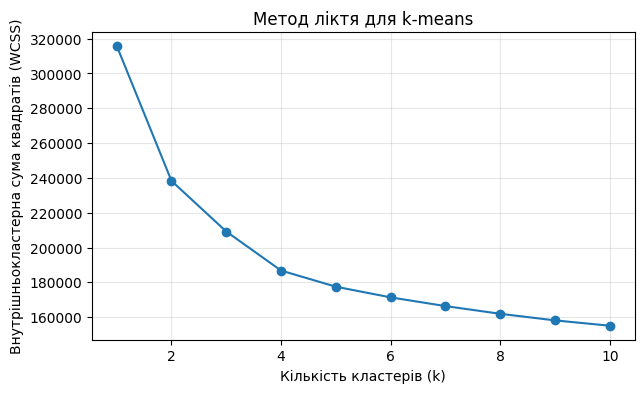

In [14]:
plt.figure(figsize=(7, 4))
plt.plot(list(k_values), inertias, marker="o")
plt.title("Метод ліктя для k-means")
plt.xlabel("Кількість кластерів (k)")
plt.ylabel("Внутрішньокластерна сума квадратів (WCSS)")
plt.grid(alpha=0.3)
plt.show()

Inertia (WCSS) з ростом k завжди зменшується, бо кластерів більше і точки ближче до своїх центроїдів. Найбільше падіння відбувається при переході від 1 до 2 кластерів (на 77 647), далі 29 094 (до k = 3) і 22 423 (до k = 4). Після k = 4 кожен новий кластер дає лише 3-9 тисяч, тобто «лікоть» знаходиться в районі k = 2-4. Найбільш виражений злам при k = 2. Остаточний вибір зробимо разом із Silhouette Score.

## 7. Оцінювання якості k-means

In [15]:
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

kmeans_metrics = []

for k in range(2, 11):
    labels = kmeans_models[k].labels_
    kmeans_metrics.append({
        "k": k,
        "Silhouette": silhouette_score(X_scaled, labels, sample_size=3000, random_state=42),
        "Davies-Bouldin": davies_bouldin_score(X_scaled, labels),
        "Calinski-Harabasz": calinski_harabasz_score(X_scaled, labels)
    })

kmeans_metrics = pd.DataFrame(kmeans_metrics)
kmeans_metrics.round(3)

,k,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,2,0.268,1.278,2287.069
1,3,0.205,2.034,1790.387
2,4,0.223,1.818,1617.480
3,5,0.188,2.038,1368.057
4,6,0.174,2.268,1183.494
5,7,0.123,2.375,1051.027
6,8,0.118,2.442,952.704
7,9,0.112,2.434,874.511
8,10,0.109,2.489,807.933


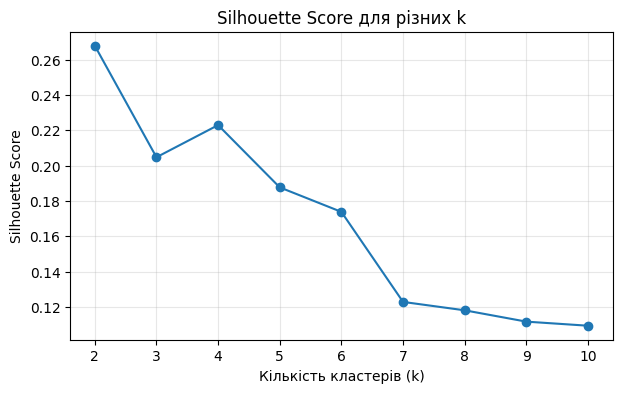

In [16]:
plt.figure(figsize=(7, 4))
plt.plot(kmeans_metrics["k"], kmeans_metrics["Silhouette"], marker="o")
plt.title("Silhouette Score для різних k")
plt.xlabel("Кількість кластерів (k)")
plt.ylabel("Silhouette Score")
plt.grid(alpha=0.3)
plt.show()

In [17]:
best_k = int(kmeans_metrics.loc[kmeans_metrics["Silhouette"].idxmax(), "k"])
kmeans_labels = kmeans_models[best_k].labels_

print("Обране k:", best_k)
print("Розміри кластерів:")
print(pd.Series(kmeans_labels).value_counts().sort_index())

Обране k: 2
Розміри кластерів:
0    5509
1    1512
Name: count, dtype: int64


In [18]:
profile = df.copy()
profile["Кластер"] = kmeans_labels

cluster_profile = pd.DataFrame({
    "Кількість": profile["Кластер"].value_counts().sort_index(),
    "tenure": profile.groupby("Кластер")["tenure"].mean(),
    "MonthlyCharges": profile.groupby("Кластер")["MonthlyCharges"].mean(),
    "Без інтернету, частка": (profile["InternetService"] == "No").groupby(profile["Кластер"]).mean(),
    "Помісячний контракт, частка": (profile["Contract"] == "Month-to-month").groupby(profile["Кластер"]).mean(),
    "Частка відтоку": churn.groupby(profile["Кластер"]).mean()
})
cluster_profile.round(2)

,Кількість,tenure,MonthlyCharges,"Без інтернету, частка","Помісячний контракт, частка",Частка відтоку
Кластер,,,,,,
0,5509,32.92,76.86,0.0,0.61,0.32
1,1512,30.82,21.09,1.0,0.34,0.07


**Метрики.** Найкращий Silhouette Score при k = 2 (0.268). При k = 2 також найкращі обидві інші метрики: найменший Davies-Bouldin (1.278, чим менше, тим краще) і найбільший Calinski-Harabasz (2287, чим більше, тим краще). Зі збільшенням k Silhouette падає до 0.109 при k = 10. Тому обрано **k = 2**: це узгоджується і з методом ліктя, де найбільший злам саме при k = 2. Значення Silhouette близько 0.27 означає, що кластери відокремлені, але не ідеально: багато клієнтів лежать недалеко від межі.

**Що це за кластери.** Кластер 1 (1512 клієнтів) - це **усі клієнти без інтернету** (частка 1.0). Вони платять у середньому лише 21.09 на місяць і майже не йдуть (відтік 7%). Кластер 0 (5509 клієнтів) - клієнти з інтернетом, з середнім платежем 76.86, у 61% помісячний контракт, відтік 32%. Отже, k-means самостійно, без цільової змінної, знайшов найсильнішу структуру в даних: наявність інтернету. Вона змінює значення відразу семи One-Hot ознак (усіх «No internet service»), тому дає найбільшу відстань між групами.

## 8. Кластеризація DBSCAN

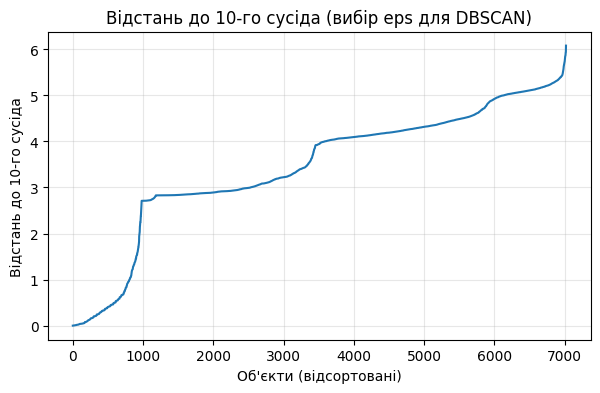

Значення eps для дослідження: [2.86 3.95 4.39 5.05 5.17]


In [19]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

neighbors = NearestNeighbors(n_neighbors=10)
neighbors.fit(X_scaled)
distances, indices = neighbors.kneighbors(X_scaled)
k_distances = np.sort(distances[:, -1])

eps_values = np.round(np.quantile(k_distances, [0.25, 0.5, 0.75, 0.9, 0.95]), 2)

plt.figure(figsize=(7, 4))
plt.plot(k_distances)
plt.title("Відстань до 10-го сусіда (вибір eps для DBSCAN)")
plt.xlabel("Об'єкти (відсортовані)")
plt.ylabel("Відстань до 10-го сусіда")
plt.grid(alpha=0.3)
plt.show()

print("Значення eps для дослідження:", eps_values)

Для кожного клієнта знайдено відстань до 10-го найближчого сусіда і відсортовано ці відстані. На графіку видно кілька «сходинок». Перші приблизно 1000 клієнтів мають майже нульову відстань, тобто в даних багато однакових або дуже схожих клієнтів (наприклад, клієнти без інтернету з однаковим набором послуг). Далі йдуть рівні близько 2.8-3.2, 4.0-4.5 і 5.0-5.2, а в кінці різкий злам вгору, де лежать найбільш віддалені, нетипові клієнти. Як кандидати для eps взято квантилі цієї відстані: 2.86, 3.95, 4.39, 5.05 і 5.17.

## 9. Вплив параметрів DBSCAN

In [20]:
min_samples_values = [5, 10, 20]
db_results = []
db_labels = {}

for eps in eps_values:
    for min_samples in min_samples_values:
        labels = DBSCAN(eps=float(eps), min_samples=min_samples).fit_predict(X_scaled)
        mask = labels != -1
        n_clusters = len(set(labels[mask]))
        noise = (labels == -1).sum()

        score = np.nan
        if n_clusters >= 2:
            score = silhouette_score(X_scaled[mask], labels[mask], sample_size=min(3000, mask.sum()), random_state=42)

        db_results.append({
            "eps": eps,
            "min_samples": min_samples,
            "Кластери": n_clusters,
            "Шум": noise,
            "Частка шуму": noise / len(labels),
            "Silhouette": score
        })
        db_labels[(eps, min_samples)] = labels

db_results = pd.DataFrame(db_results)
db_results.round(3)

,eps,min_samples,Кластери,Шум,Частка шуму,Silhouette
0,2.86,5,140,4076,0.581,0.275
1,2.86,10,61,4840,0.689,0.295
2,2.86,20,24,5615,0.800,0.323
3,3.95,5,23,1572,0.224,0.040
4,3.95,10,4,2382,0.339,0.195
5,3.95,20,4,3073,0.438,0.325
6,4.39,5,4,193,0.027,0.228
7,4.39,10,5,604,0.086,0.165
8,4.39,20,3,1190,0.169,0.275
9,5.05,5,3,19,0.003,0.266


Таблиця показує, як параметри змінюють результат:
- **Мале eps (2.86):** сусідні області маленькі, тому утворюється багато дрібних кластерів (24-140), а 58-80% клієнтів потрапляє в шум. Такий результат непридатний.
- **eps = 3.95:** 4-23 кластери, шум 22-44%, теж забагато.
- **eps = 4.39:** 3-5 кластерів, шум 3-17%.
- **Великі eps (5.05-5.17):** стабільно 3 кластери і майже немає шуму (0.1-4%).
- **min_samples:** чим він більший, тим суворіша вимога до щільності. При тому самому eps шуму стає більше (наприклад, при eps = 4.39 шум 193, 604 і 1190 для min_samples 5, 10 і 20).

Високий Silhouette при eps = 2.86 (0.32) оманливий: його пораховано лише для невеликої частини клієнтів, які не потрапили в шум.

## 10. Оцінювання якості DBSCAN

In [21]:
valid = db_results[(db_results["Кластери"] >= 2) & (db_results["Частка шуму"] <= 0.1)]
best = valid.loc[valid["Silhouette"].idxmax()]

best_eps = best["eps"]
best_min_samples = int(best["min_samples"])
dbscan_labels = db_labels[(best_eps, best_min_samples)]

print("Обрана конфігурація DBSCAN: eps =", best_eps, " min_samples =", best_min_samples)
print("Кластерів:", int(best["Кластери"]), " Шум:", int(best["Шум"]), " Silhouette:", round(best["Silhouette"], 3))
print("Розміри груп (-1 = шум):")
print(pd.Series(dbscan_labels).value_counts().sort_index())

Обрана конфігурація DBSCAN: eps = 5.05  min_samples = 10
Кластерів: 3  Шум: 64  Silhouette: 0.266
Розміри груп (-1 = шум):
-1      64
 0     638
 1    4807
 2    1512
Name: count, dtype: int64


In [22]:
db_profile = df.copy()
db_profile["Кластер"] = dbscan_labels

pd.DataFrame({
    "Кількість": db_profile["Кластер"].value_counts().sort_index(),
    "tenure": db_profile.groupby("Кластер")["tenure"].mean(),
    "MonthlyCharges": db_profile.groupby("Кластер")["MonthlyCharges"].mean(),
    "Без інтернету, частка": (db_profile["InternetService"] == "No").groupby(db_profile["Кластер"]).mean(),
    "Без телефону, частка": (db_profile["PhoneService"] == "No").groupby(db_profile["Кластер"]).mean(),
    "Частка відтоку": churn.groupby(db_profile["Кластер"]).mean()
}).round(2)

,Кількість,tenure,MonthlyCharges,"Без інтернету, частка","Без телефону, частка",Частка відтоку
Кластер,,,,,,
-1,64,43.70,58.55,0.0,0.69,0.08
0,638,30.93,41.66,0.0,1.00,0.26
1,4807,33.04,81.78,0.0,0.00,0.33
2,1512,30.82,21.09,1.0,0.00,0.07


Конфігурацію обрано так: щонайменше 2 кластери, шум не більше 10%, максимальний Silhouette. Найкраща **eps = 5.05, min_samples = 10**: 3 кластери, 64 шумові об'єкти (0.9%), Silhouette 0.266.

**Що це за кластери:**
- **кластер 2 (1512):** клієнти без інтернету, такий самий, як кластер 1 у k-means; відтік 7%;
- **кластер 0 (638):** клієнти з інтернетом, але **без телефонного зв'язку** (частка 1.0), середній платіж 41.66, відтік 26%;
- **кластер 1 (4807):** клієнти з інтернетом і телефоном, найвищий платіж (81.78) і найвищий відтік (33%);
- **шум (64):** нетипові клієнти з незвичним поєднанням послуг, у середньому довше з компанією (tenure 43.7) і з низьким відтоком (8%).

Тобто DBSCAN знайшов ще одну природну групу, клієнтів без телефону, яку k-means при k = 2 не відокремив, і виділив невелику кількість нетипових об'єктів.

## 11. Порівняння k-means і DBSCAN

In [23]:
db_mask = dbscan_labels != -1

comparison = pd.DataFrame([
    {
        "Метод": "k-means (k = " + str(best_k) + ")",
        "Кластерів": len(set(kmeans_labels)),
        "Шум": 0,
        "Silhouette": silhouette_score(X_scaled, kmeans_labels, sample_size=3000, random_state=42),
        "Davies-Bouldin": davies_bouldin_score(X_scaled, kmeans_labels),
        "Calinski-Harabasz": calinski_harabasz_score(X_scaled, kmeans_labels)
    },
    {
        "Метод": "DBSCAN (без шуму)",
        "Кластерів": len(set(dbscan_labels[db_mask])),
        "Шум": (~db_mask).sum(),
        "Silhouette": silhouette_score(X_scaled[db_mask], dbscan_labels[db_mask], sample_size=3000, random_state=42),
        "Davies-Bouldin": davies_bouldin_score(X_scaled[db_mask], dbscan_labels[db_mask]),
        "Calinski-Harabasz": calinski_harabasz_score(X_scaled[db_mask], dbscan_labels[db_mask])
    }
])
comparison.round(3)

,Метод,Кластерів,Шум,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,k-means (k = 2),2,0,0.268,1.278,2287.069
1,DBSCAN (без шуму),3,64,0.266,1.564,1672.648


In [24]:
from sklearn.metrics import adjusted_rand_score

rng = np.random.default_rng(42)
stability = []

for i in range(3):
    idx = rng.choice(len(X_scaled), size=int(0.8 * len(X_scaled)), replace=False)
    X_sub = X_scaled[idx]

    km_sub = KMeans(n_clusters=best_k, n_init=10, random_state=42 + i).fit_predict(X_sub)
    db_sub = DBSCAN(eps=float(best_eps), min_samples=best_min_samples).fit_predict(X_sub)

    stability.append({
        "Повтор": i + 1,
        "k-means ARI": adjusted_rand_score(kmeans_labels[idx], km_sub),
        "DBSCAN ARI": adjusted_rand_score(dbscan_labels[idx], db_sub)
    })

stability = pd.DataFrame(stability)
stability.round(3)

,Повтор,k-means ARI,DBSCAN ARI
0,1,1.0,0.986
1,2,1.0,0.986
2,3,1.0,0.984


In [25]:
pd.crosstab(pd.Series(kmeans_labels, name="k-means"), pd.Series(dbscan_labels, name="DBSCAN"))

DBSCAN,-1,0,1,2
k-means,,,,
0,64,638,4807,0
1,0,0,0,1512


| Критерій | k-means (k = 2) | DBSCAN (eps 5.05, min_samples 10) |
|---|---|---|
| Кількість кластерів | 2, задано вручну | 3, визначено автоматично |
| Silhouette | 0.268 | 0.266 (без шуму) |
| Davies-Bouldin | **1.278** | 1.564 |
| Calinski-Harabasz | **2287** | 1673 |
| Шум | немає, кожен клієнт у кластері | 64 об'єкти (0.9%) |
| Стабільність (ARI) | **1.000** | 0.984-0.986 |

- **Метрики якості.** За Silhouette методи майже рівні. За Davies-Bouldin і Calinski-Harabasz k-means кращий, бо ці метрики «люблять» компактні сферичні кластери, а саме такі будує k-means.
- **Шум.** k-means не вміє виділяти шум, він відносить кожного клієнта до найближчого центру. DBSCAN окремо позначив 64 нетипових клієнти.
- **Стабільність.** Обидва методи дуже стабільні. На трьох випадкових підвибірках по 80% k-means дає ті самі кластери (ARI = 1.0), DBSCAN майже ті самі (ARI 0.98-0.99). Невелика нестабільність DBSCAN пов'язана з тим, що при меншій кількості точок частина граничних об'єктів переходить у шум.
- **Характер кластерів.** Таблиця перехресного розподілу показує, що кластери узгоджені. Кластер «без інтернету» в обох методах однаковий (1512 клієнтів). Великий кластер k-means (5509) DBSCAN розділив на клієнтів з телефоном (4807), без телефону (638) і шум (64).

## 12. PCA на стандартизованих даних

In [26]:
from sklearn.decomposition import PCA

pca_full = PCA()
pca_full.fit(X_scaled)

print("Кількість ознак:", X_scaled.shape[1])
print("Кількість головних компонент:", pca_full.n_components_)

Кількість ознак: 45
Кількість головних компонент: 45


## 13. Пояснена та накопичена дисперсія

In [27]:
variance_df = pd.DataFrame({
    "Компонента": range(1, pca_full.n_components_ + 1),
    "Пояснена дисперсія": pca_full.explained_variance_ratio_,
    "Накопичена дисперсія": np.cumsum(pca_full.explained_variance_ratio_)
})
variance_df.head(20).round(4)

,Компонента,Пояснена дисперсія,Накопичена дисперсія
0,1,0.2519,0.2519
1,2,0.1347,0.3866
2,3,0.0945,0.4811
3,4,0.0565,0.5375
4,5,0.0501,0.5876
5,6,0.0445,0.6321
6,7,0.0372,0.6693
7,8,0.0346,0.7039
8,9,0.0304,0.7343
9,10,0.0288,0.7631


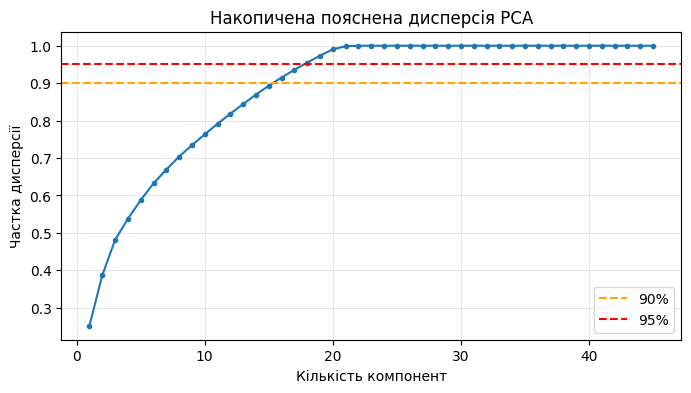

In [28]:
plt.figure(figsize=(8, 4))
plt.plot(variance_df["Компонента"], variance_df["Накопичена дисперсія"], marker="o", markersize=3)
plt.axhline(0.9, linestyle="--", color="orange", label="90%")
plt.axhline(0.95, linestyle="--", color="red", label="95%")
plt.title("Накопичена пояснена дисперсія PCA")
plt.xlabel("Кількість компонент")
plt.ylabel("Частка дисперсії")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 14. Кількість компонент для збереження інформації

In [29]:
cumulative = np.cumsum(pca_full.explained_variance_ratio_)

n_90 = int(np.argmax(cumulative >= 0.9) + 1)
n_95 = int(np.argmax(cumulative >= 0.95) + 1)
zero_components = int((pca_full.explained_variance_ratio_ < 1e-6).sum())

print("Компонент для 90% дисперсії:", n_90)
print("Компонент для 95% дисперсії:", n_95)
print("Компонент з майже нульовою дисперсією:", zero_components)

Компонент для 90% дисперсії: 16
Компонент для 95% дисперсії: 18
Компонент з майже нульовою дисперсією: 22


Перша компонента пояснює 25.2% дисперсії, друга 13.5%, третя 9.5%, далі внесок кожної компоненти поступово зменшується до 1.7-2.6%. Щоб зберегти **90%** інформації, потрібно **16** компонент, для **95%** потрібно **18**. Обрано 18 компонент (95%): це стандартний рівень, при якому втрачається лише 5% інформації, а кількість ознак зменшується з 45 до 18, тобто в 2.5 рази.

**22 компоненти мають майже нульову дисперсію.** Це наслідок One-Hot кодування. У кожній закодованій ознаці стовпці в сумі дають 1 (наприклад, `gender_Female` + `gender_Male` = 1), тобто один стовпець завжди можна обчислити з інших. Крім того, шість стовпців «No internet service» повністю дублюють `InternetService_No`. Тому реальна «розмірність» даних помітно менша за 45, і PCA це показує. На графіку накопичена дисперсія після 20 компонент виходить на 100%.

## 15. Зниження розмірності до двох компонент

In [30]:
pca_2 = PCA(n_components=2)
X_pca = pca_2.fit_transform(X_scaled)

print("Розмір після PCA:", X_pca.shape)
print("Дисперсія PC1:", round(pca_2.explained_variance_ratio_[0], 3))
print("Дисперсія PC2:", round(pca_2.explained_variance_ratio_[1], 3))
print("Разом дві компоненти:", round(pca_2.explained_variance_ratio_.sum(), 3))

Розмір після PCA: (7021, 2)
Дисперсія PC1: 0.252
Дисперсія PC2: 0.135
Разом дві компоненти: 0.387


In [31]:
loadings = pd.DataFrame(pca_2.components_.T, columns=["PC1", "PC2"], index=X.columns)
print("Ознаки з найбільшим внеском у PC1:")
print(loadings["PC1"].abs().sort_values(ascending=False).head(5).round(3))
print()
print("Ознаки з найбільшим внеском у PC2:")
print(loadings["PC2"].abs().sort_values(ascending=False).head(5).round(3))

Ознаки з найбільшим внеском у PC1:
TechSupport_No internet service         0.292
OnlineBackup_No internet service        0.292
DeviceProtection_No internet service    0.292
InternetService_No                      0.292
OnlineSecurity_No internet service      0.292
Name: PC1, dtype: float64

Ознаки з найбільшим внеском у PC2:
tenure                     0.332
TotalCharges               0.321
Contract_Month-to-month    0.288
Contract_Two year          0.239
Partner_Yes                0.215
Name: PC2, dtype: float64


Дві перші компоненти разом пояснюють лише **38.7%** дисперсії (25.2% + 13.5%). Отже, двовимірна картинка показує трохи більше третини всієї інформації.

Компоненти можна інтерпретувати через ознаки з найбільшим внеском:
- **PC1** - це «наявність інтернету». Найбільший внесок мають `InternetService_No` і всі стовпці «No internet service» (по 0.292);
- **PC2** - це «тривалість обслуговування і контракт». Найбільший внесок мають `tenure` (0.332), `TotalCharges` (0.321), `Contract_Month-to-month` і `Contract_Two year`.

## 16. Візуалізація кластерів у просторі PCA

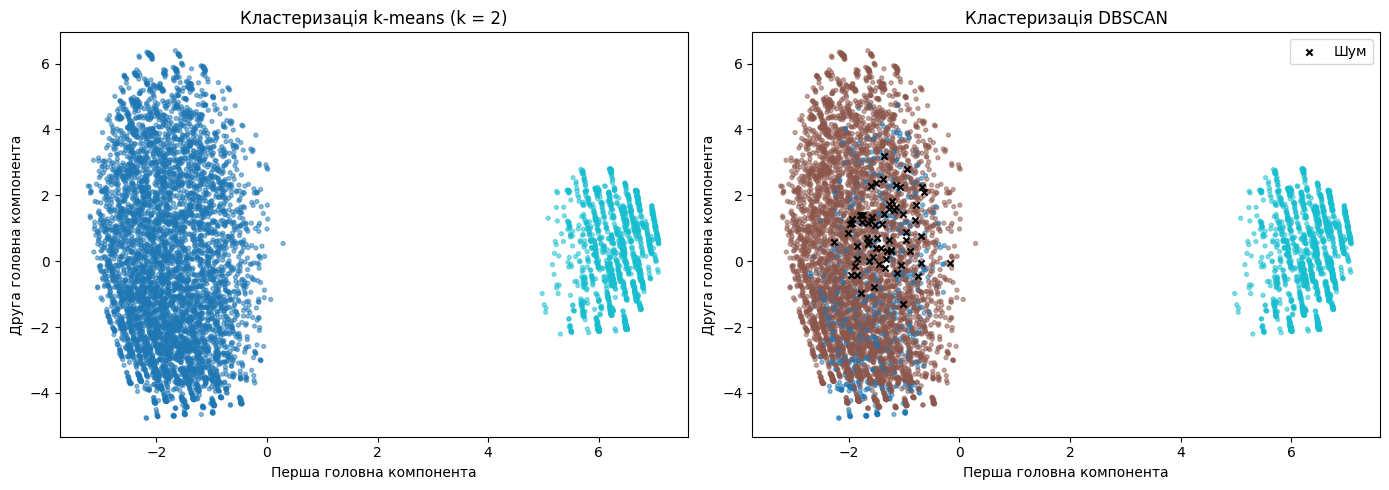

In [32]:
noise = dbscan_labels == -1

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels, cmap="tab10", s=8, alpha=0.5)
axes[0].set_title("Кластеризація k-means (k = " + str(best_k) + ")")

axes[1].scatter(X_pca[~noise, 0], X_pca[~noise, 1], c=dbscan_labels[~noise], cmap="tab10", s=8, alpha=0.5)
axes[1].scatter(X_pca[noise, 0], X_pca[noise, 1], c="black", marker="x", s=20, label="Шум")
axes[1].set_title("Кластеризація DBSCAN")
axes[1].legend()

for ax in axes:
    ax.set_xlabel("Перша головна компонента")
    ax.set_ylabel("Друга головна компонента")

plt.tight_layout()
plt.show()

## 17. Аналіз візуалізацій

- **Розділення кластерів.** Кластер «без інтернету» дуже чітко відокремлений від решти: він лежить праворуч (PC1 близько 5-7), а всі інші клієнти ліворуч (PC1 від -3 до 0), і між ними широкий порожній проміжок. Це добре узгоджується з тим, що PC1 - це саме «наявність інтернету».
- **Перекриття.** На діаграмі DBSCAN кластер «без телефону» (638 клієнтів) накладається на великий кластер. Це не означає, що вони справді змішані: ознака телефону майже не входить у перші дві компоненти, тому в цій проекції їх не видно. У повному 45-вимірному просторі DBSCAN їх розділив.
- **Компактність.** Кластер «без інтернету» компактніший і менший. Великий кластер витягнутий по вертикалі (PC2), бо клієнти з інтернетом сильно відрізняються за тривалістю обслуговування і типом контракту. Видні «смужки» - це наслідок дискретних значень One-Hot ознак і `tenure`.
- **Шум.** Шумові об'єкти DBSCAN (чорні хрестики) лежать не на краю, а всередині великої хмари. Тобто вони нетипові в повному просторі ознак (незвичне поєднання послуг), але в двох перших компонентах цього не видно. Це ще раз показує, що 2D-проекція відображає лише частину структури.

## 18. Порівняння початкового простору ознак і PCA

Початковий простір має 45 ознак, з яких багато дублюють одна одну через One-Hot кодування. PCA показав, що:
- **18 компонент зберігають 95.5%** дисперсії, тобто розмірність можна зменшити в 2.5 рази майже без втрати інформації;
- **16 компонент зберігають 90%**;
- **2 компоненти зберігають лише 38.7%**. Цього достатньо, щоб побачити головну структуру (чітке відокремлення клієнтів без інтернету), але недостатньо, щоб побачити все. Наприклад, кластер без телефону і шумові об'єкти в 2D не відокремлюються.

Отже, PCA доцільний для візуалізації і для стиснення даних перед іншими алгоритмами, але висновки з 2D-графіка треба перевіряти метриками в повному просторі.

## 19. Висновки

- **Принципи і результати.** k-means ділить дані на задану кількість кластерів, мінімізуючи відстані до центроїдів, і кожен об'єкт обов'язково потрапляє в якийсь кластер. DBSCAN шукає області високої щільності, сам визначає кількість кластерів і окремо позначає шум. На цих даних k-means при k = 2 відокремив клієнтів без інтернету (1512) від решти (5509), а DBSCAN знайшов 3 кластери: без інтернету (1512), з інтернетом, але без телефону (638), з інтернетом і телефоном (4807), а також 64 шумові об'єкти.
- **Вибір параметрів.** Для k-means k = 2 обрано за найбільшим Silhouette (0.268), найкращими Davies-Bouldin і Calinski-Harabasz і найсильнішим зламом на графіку ліктя. Для DBSCAN eps підбирався за графіком відстаней до 10-го сусіда, а конфігурацію eps = 5.05, min_samples = 10 обрано як найкращу за Silhouette серед варіантів з 2+ кластерами і шумом до 10%. Малі eps дають сотні кластерів і багато шуму, великі min_samples збільшують шум.
- **Доцільність PCA.** PCA зменшив 45 ознак до 18 компонент зі збереженням 95% дисперсії, а також виявив надлишковість One-Hot ознак (22 компоненти з нульовою дисперсією). Двовимірне представлення пояснює лише 38.7% дисперсії, але добре показує головну структуру даних і дозволяє інтерпретувати компоненти: PC1 - наявність інтернету, PC2 - тривалість обслуговування і контракт.
- **Який метод краще відображає структуру.** За внутрішніми метриками і стабільністю k-means трохи кращий. Проте DBSCAN дає змістовніший результат: він сам визначив кількість груп, знайшов додатковий природний сегмент (клієнти без телефону) і виділив нетипові об'єкти. Кластери обох методів мають чіткий зміст і різний рівень відтоку (7%, 26% і 33%), хоча `Churn` у кластеризації не використовувався. Тому для опису структури цих даних краще підходить **DBSCAN**, а k-means доцільний, якщо потрібен простий поділ на задану кількість груп.